# 06 · Uncertainty, Probability and Quantiles

Unit 1: mean, variance, probability densities, expectation, covariance, quantiles — connected to safety-stock sizing.

> **Data provenance.** Sales, dates, prices, SKUs and countries are **real**
> (UCI Online Retail II, CC BY 4.0, 1,067,371 invoice lines).
> Stock levels, suppliers, lead times, MOQ, pack sizes and every cost are
> **SIMULATED** — the source dataset contains none of them. See `sim/` and
> `docs/pbl1_scope.md`.


In [1]:
import sys, os
from pathlib import Path
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(_v, "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 60)

from xaierp.utils.config import load_config, resolve
CFG = load_config()
REPORTS = resolve(CFG["paths"]["reports"])
FIGS = resolve(CFG["paths"]["figures"])
print("project root:", ROOT)


project root: E:\downloads\ML Project


## Mean, variance and the shape of demand

In [2]:
panel = pd.read_parquet(
    resolve(CFG['paths']['processed']) / 'daily_demand_panel.parquet')
d = panel['demand']
stats = pd.Series({
    'mean E[X]': d.mean(), 'variance Var(X)': d.var(),
    'std sqrt(Var)': d.std(), 'median': d.median(),
    'skewness': d.skew(), 'kurtosis': d.kurtosis(),
    'min': d.min(), 'max': d.max()})
display(stats.to_frame('daily demand per SKU').round(3))
print('Var(X) = E[X^2] - (E[X])^2 check:',
      round((d**2).mean() - d.mean()**2, 4), 'vs', round(d.var(ddof=0), 4))

,daily demand per SKU
mean E[X],28.626
variance Var(X),8890.773
std sqrt(Var),94.291
median,6.000
skewness,24.566
kurtosis,1416.145
min,0.000
max,9480.000


Var(X) = E[X^2] - (E[X])^2 check: 8890.6999 vs 8890.6999


The identity `Var(X) = E[X²] − (E[X])²` from Unit 1 is verified numerically above. Mean far exceeds median and skewness is large — this is nothing like a Normal distribution, which matters later.

## Empirical quantiles of 7-day demand

In [3]:
feats = pd.read_parquet(
    resolve(CFG['paths']['processed']) / 'feature_table.parquet')
y = feats['future_7d_demand']
qs = [0.5, 0.75, 0.9, 0.95, 0.99]
q = pd.DataFrame({'quantile': qs, 'units over 7 days': [y.quantile(v) for v in qs]})
q['x P50'] = (q['units over 7 days'] / y.quantile(0.5)).round(2)
display(q.round(1))
print('Planning to P95 instead of P50 means holding',
      f"{y.quantile(0.95)/y.quantile(0.5):.1f}x the stock.")

,quantile,units over 7 days,x P50
0,0.5,119.0,1.0
1,0.8,282.0,2.4
2,0.9,538.0,4.5
3,1.0,784.0,6.6
4,1.0,1671.0,14.0


Planning to P95 instead of P50 means holding 6.6x the stock.


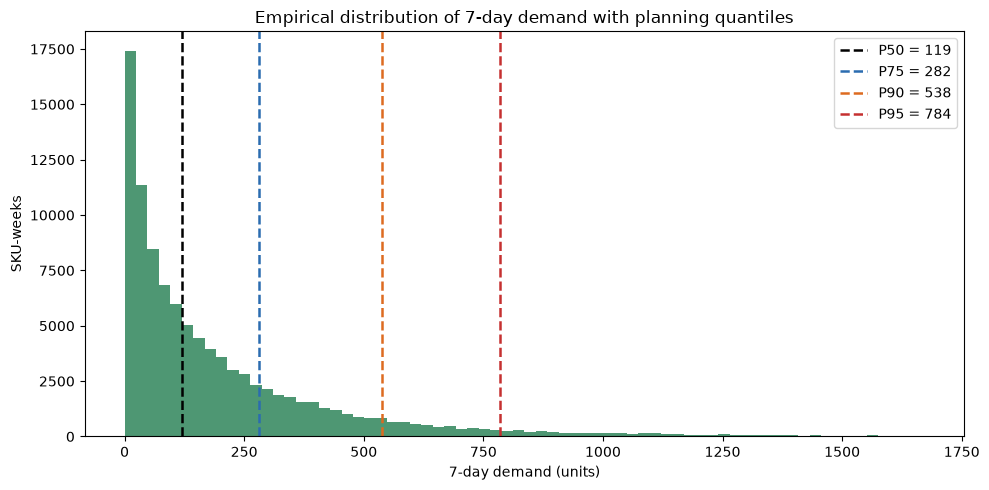

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(y[y <= y.quantile(0.99)], bins=70, color='#2f855a', alpha=0.85)
for v, c in zip([0.5, 0.75, 0.9, 0.95], ['k', '#2b6cb0', '#dd6b20', '#c53030']):
    ax.axvline(y.quantile(v), ls='--', color=c, lw=1.8,
               label=f'P{int(v*100)} = {y.quantile(v):,.0f}')
ax.set_xlabel('7-day demand (units)'); ax.set_ylabel('SKU-weeks')
ax.set_title('Empirical distribution of 7-day demand with planning quantiles')
ax.legend(); plt.tight_layout(); plt.show()

## Covariance and correlation (Unit 1)

In [5]:
cols = ['demand', 'revenue', 'avg_price', 'n_invoices', 'returned_units']
print('Covariance matrix:'); display(panel[cols].cov().round(2))
print('Correlation matrix:'); display(panel[cols].corr().round(3))

Covariance matrix:


,demand,revenue,avg_price,n_invoices,returned_units
demand,8890.77,13772.28,-60.76,89.19,447.27
revenue,13772.28,52343.47,88.79,224.10,869.21
avg_price,-60.76,88.79,23.72,-1.53,-1.14
n_invoices,89.19,224.10,-1.53,6.21,2.39
returned_units,447.27,869.21,-1.14,2.39,3218.65


Correlation matrix:


,demand,revenue,avg_price,n_invoices,returned_units
demand,1.000,0.638,-0.132,0.380,0.084
revenue,0.638,1.000,0.080,0.393,0.067
avg_price,-0.132,0.080,1.000,-0.126,-0.004
n_invoices,0.380,0.393,-0.126,1.000,0.017
returned_units,0.084,0.067,-0.004,0.017,1.000


Covariance is scale-dependent (its units are units×currency), which is why correlation — covariance divided by the two standard deviations — is the comparable quantity.

## Learned quantiles: does P90 really cover 90%?

,quantile,pinball_loss_test,empirical_coverage_test,coverage_error,mean_prediction,train_time_s
0,0.50,63.1899,0.5504,0.0504,212.2319,6.060
1,0.75,66.0630,0.7582,0.0082,312.4889,6.097
2,0.90,49.5083,0.8923,-0.0077,441.1861,4.859
3,0.95,37.7596,0.9289,-0.0211,520.7031,5.648


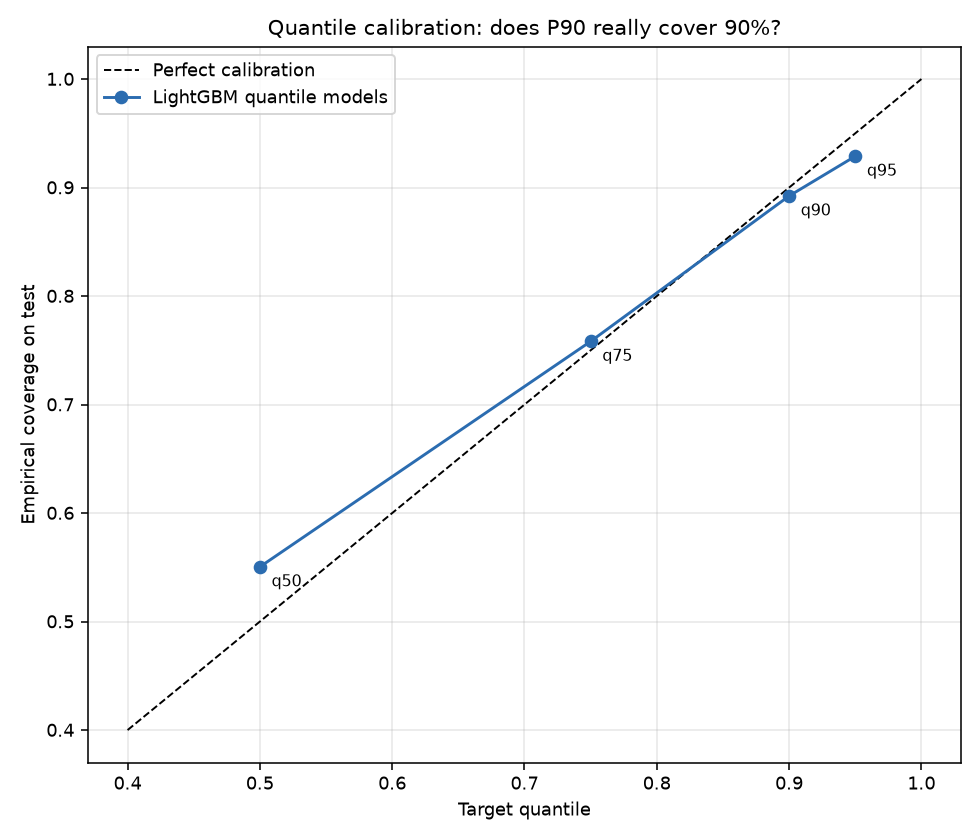

In [6]:
qt = pd.read_csv(REPORTS / 'quantile_model_metrics.csv')
display(qt.round(4))
from IPython.display import Image, display
display(Image(filename=str(FIGS / 'model_quantile_calibration.png')))

These are LightGBM models trained on the **pinball loss**, which is the proper scoring rule for a quantile. Coverage is within a few points of target, so the predicted upper quantile is a usable basis for safety stock — and unlike the classical `z·σ·√L` formula it makes no Normality assumption, which matters given the skew measured above.

## From quantile to safety stock

In [7]:
from xaierp.policy.reorder import safety_stock_from_quantiles, safety_stock_from_sigma
sigma, lead = float(panel['demand'].std()), 7
rows = []
for sl in [0.50, 0.75, 0.90, 0.95, 0.99]:
    rows.append({'service level': sl,
                 'classical z*sigma*sqrt(L)': round(safety_stock_from_sigma(sigma, lead, sl), 1)})
display(pd.DataFrame(rows))
preds = pd.read_parquet(resolve(CFG['paths']['forecasts']) / 'test_predictions.parquet')
gap = (preds['pred_q95'].clip(lower=0) - preds['pred_q50'].clip(lower=0)).clip(lower=0)
print(f'\nLearned P95-P50 buffer: mean {gap.mean():.1f}, median {gap.median():.1f} units')

,service level,classical z*sigma*sqrt(L)
0,0.50,0.0
1,0.75,168.3
2,0.90,319.7
3,0.95,410.3
4,0.99,580.4



Learned P95-P50 buffer: mean 308.5, median 257.6 units
